## Ejercicio 5

Trabajo Práctico — Reconstrucción y regularización en imágenes tomográficas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [2]:
X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = X_fantoma.shape[0]
x_fantoma = X_fantoma.reshape(-1)

In [3]:
def mascara_rayo(n, direccion, s):
    alfa = direccion[0]
    beta = direccion[1]
    matriz = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(n):
            if alfa * i + beta * j == s:
                matriz[i][j] = 1
    return matriz


def matriz_proyeccion(n, direcciones):
    filas_A = []
    rayos = []

    for direccion in direcciones:
        alfa = direccion[0]
        beta = direccion[1]
        valores_s = set()

        for i in range(n):
            for j in range(n):
                valores_s.add(alfa * i + beta * j)

        for s in sorted(valores_s):
            mascara = mascara_rayo(n, direccion, s)
            filas_A.append(mascara.reshape(-1))
            rayos.append((direccion, s))

    A = np.array(filas_A, dtype=float)
    return A, rayos

In [4]:
D2 = [(1, 0), (0, 1)]
D4 = D2 + [(1, 1), (1, -1)]
D7 = D4 + [(2, 1), (1, 2), (3, 1)]

A2, rayos2 = matriz_proyeccion(n, D2)
A4, rayos4 = matriz_proyeccion(n, D4)
A7, rayos7 = matriz_proyeccion(n, D7)

### Inciso a)

In [5]:
matrices = {2: A2, 4: A4, 7: A7}
mediciones = {}
reconstrucciones = {}

for k, A in matrices.items():
    b = A @ x_fantoma
    x_rec = np.linalg.lstsq(A, b, rcond=None)[0]
    mediciones[k] = b
    reconstrucciones[k] = x_rec

`lstsq` busca la imagen que minimiza la norma del residuo. Como las mediciones son ideales,
hay soluciones con residuo prácticamente nulo. Cuando hay varias, devuelve la de menor
norma euclídea, que puede ser distinta del fantoma original.

### Inciso b)

In [6]:
print(f"{'Matriz':<8} {'Rango':>7} {'Norma residuo':>17} {'Error relativo':>17}")
for k, A in matrices.items():
    x_rec = reconstrucciones[k]
    residuo = mediciones[k] - A @ x_rec
    error = np.linalg.norm(x_rec - x_fantoma) / np.linalg.norm(x_fantoma)
    print(f"{'A' + str(k):<8} {np.linalg.matrix_rank(A):7d} {np.linalg.norm(residuo):17.6e} {error:17.6e}")
    assert np.linalg.norm(residuo) < 1e-10
assert np.allclose(reconstrucciones[7], x_fantoma)

Matriz     Rango     Norma residuo    Error relativo
A2            15      4.034489e-15      4.689265e-01
A4            39      1.508026e-14      1.364605e-01
A7            64      1.311145e-14      1.667070e-15


### Inciso c)

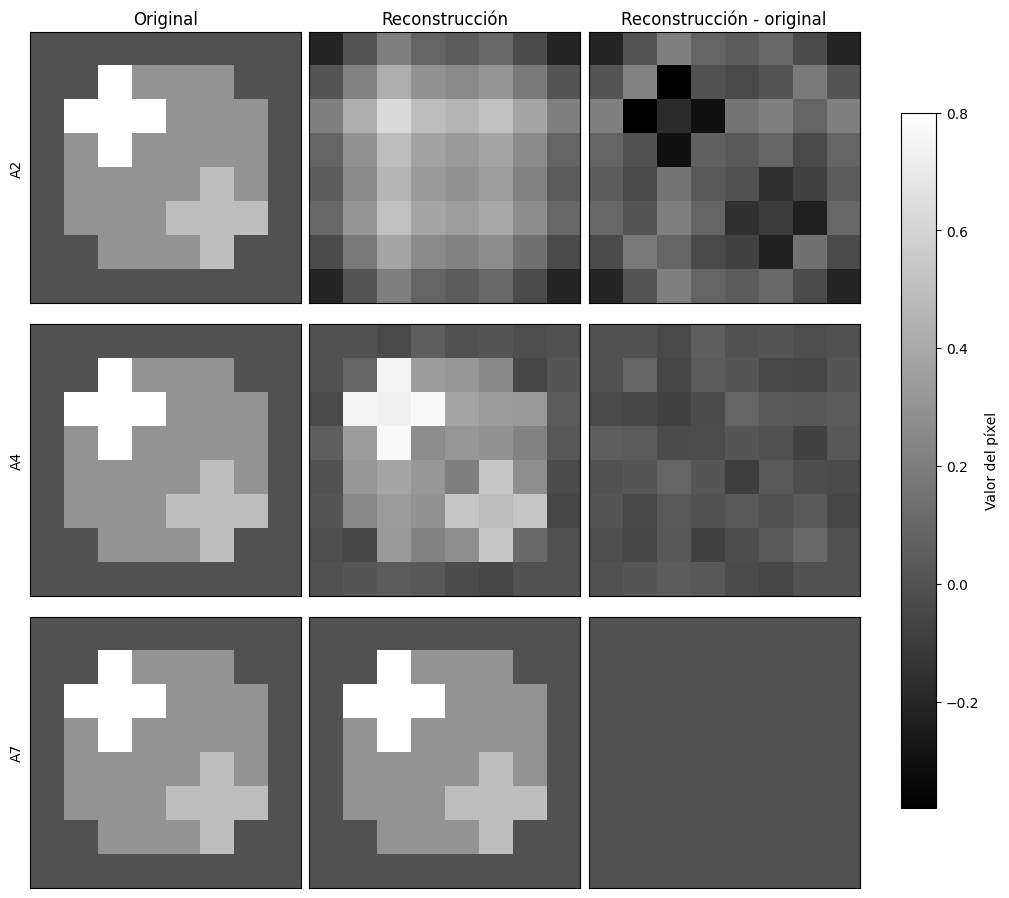

In [7]:
imagenes = []
for k in matrices:
    X_rec = reconstrucciones[k].reshape(n, n)
    imagenes.extend([X_fantoma, X_rec, X_rec - X_fantoma])
vmin = min(imagen.min() for imagen in imagenes)
vmax = max(imagen.max() for imagen in imagenes)

fig, axs = plt.subplots(3, 3, figsize=(10, 9), layout="constrained")
for fila, k in enumerate(matrices):
    X_rec = reconstrucciones[k].reshape(n, n)
    for columna, imagen in enumerate([X_fantoma, X_rec, X_rec - X_fantoma]):
        im = axs[fila, columna].imshow(imagen, cmap="gray", vmin=vmin, vmax=vmax)
        axs[fila, columna].set_xticks([])
        axs[fila, columna].set_yticks([])
    axs[fila, 0].set_ylabel(f"A{k}")
for ax, titulo in zip(axs[0], ["Original", "Reconstrucción", "Reconstrucción - original"]):
    ax.set_title(titulo)
fig.colorbar(im, ax=axs, label="Valor del píxel", shrink=0.8)
plt.show()

Con `A2` el error relativo es aproximadamente $0{,}469$ y con `A4` es $0{,}136$,
aunque ambos residuos son del orden del redondeo numérico. Con `A7` se recupera el fantoma
con error del orden de $10^{-15}$.

Un residuo casi cero solamente indica que la imagen reconstruida reproduce las mediciones.
En `A2` y `A4`, la diferencia entre la reconstrucción y el fantoma puede ser un vector no nulo
del espacio nulo. En `A7` no existe esa ambigüedad porque tiene rango columna completo.

Asistencia utilizada: ChatGPT / Codex para completar y revisar el código, las explicaciones y las verificaciones de este notebook.